Missing Values:
Country Name                                    0
Country Code                                    0
Region                                          0
IncomeGroup                                     0
Year                                            0
Birth rate per 1000 people                     95
Death rate per 1000 people                    114
Electric power consumption per capita         301
GDP                                           137
GDP per capita                                137
Individuals using the Internet                310
Infant mortality rate per 1000 live births    158
Life expectancy at birth                      126
Population density                              9
Unemployment                                  333
dtype: int64

Cleaned Data:
   Infant mortality rate per 1000 live births  Life expectancy at birth  \
0                                        47.9                    67.078   
1                                        49.5           

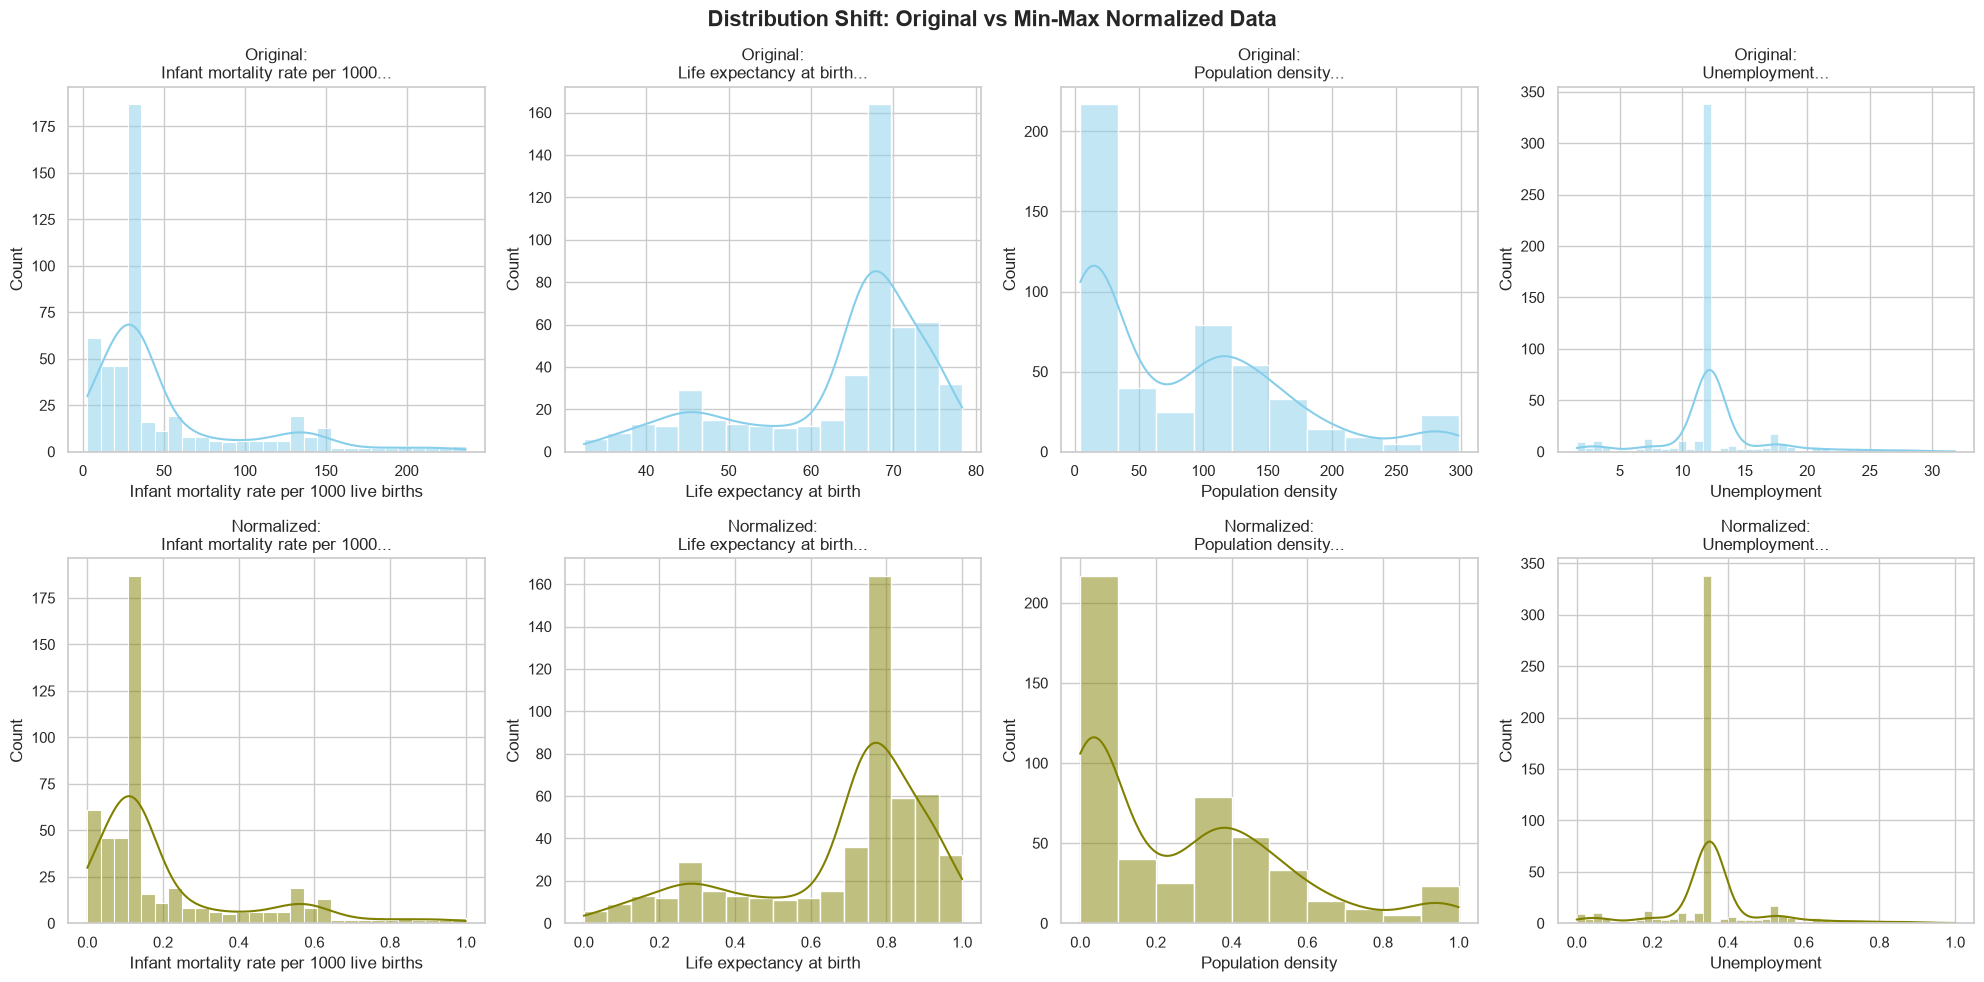

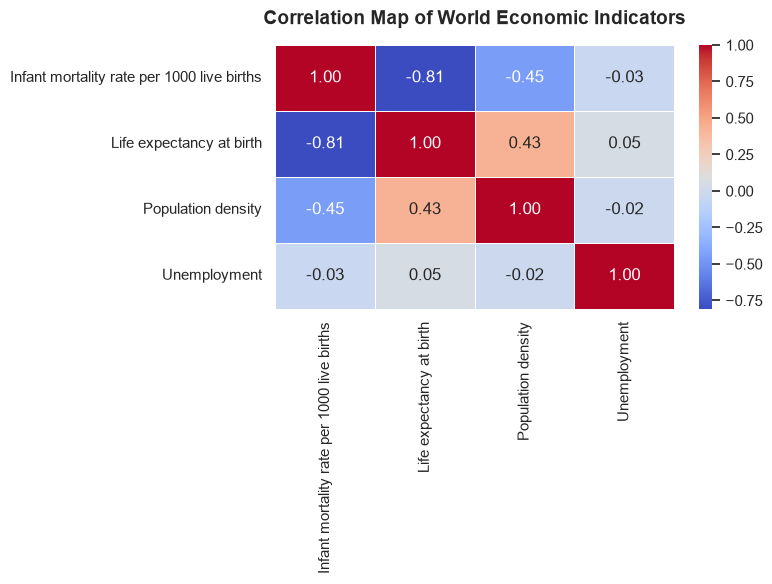

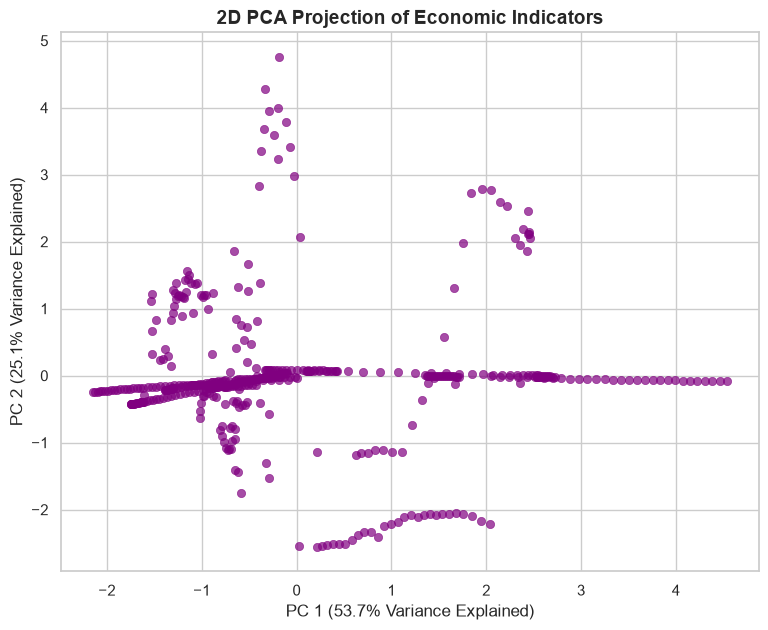

Explained variance ratio: [0.53742295 0.25131936]
Total variance captured: 78.87423093364242 %


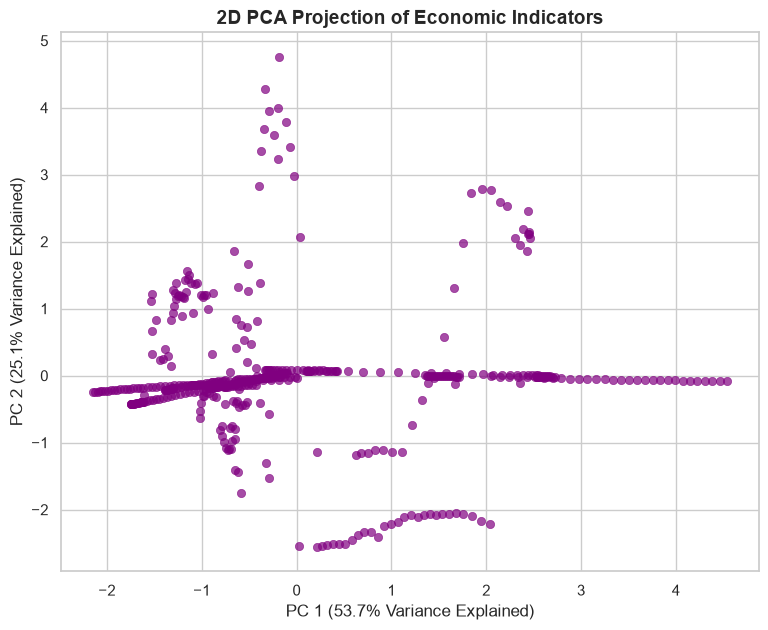

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns # Added for better statistical visualizations

df = pd.read_csv('World Economic Indicators - Sheet1.csv')
features = df[['Infant mortality rate per 1000 live births','Life expectancy at birth','Population density','Unemployment']]

# --- Data Cleaning ---

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Select required features
features = df[['Infant mortality rate per 1000 live births', 'Life expectancy at birth', 'Population density', 'Unemployment']].copy()

# Convert columns to numeric
features = features.apply(pd.to_numeric, errors='coerce')

# Replace infinite values with NaN
features = features.replace([float('inf'), float('-inf')], pd.NA)

# Fill missing values with column median
features = features.fillna(features.median())

# Remove rows if any missing values remain
features = features.dropna()

# Reset index
features = features.reset_index(drop=True)

print("\nCleaned Data:")
print(features.head())

print("\nMissing Values After Cleaning:")
print(features.isnull().sum())

print("\nCleaned Dataset Shape:", features.shape)

# --- Min-Max Normalization (scales to 0-1) ---
minmax = MinMaxScaler()
normalized_arr = minmax.fit_transform(features)
# Convert array back to a DataFrame for easier plotting
normalized_df = pd.DataFrame(normalized_arr, columns=features.columns)

print(f'\nNormalized range: Min = {normalized_arr.min()}, Max = {normalized_arr.max()}')


# ==========================================
# --- VISUALIZATION CODE ---
# ==========================================

# Set style for all plots
sns.set_theme(style="whitegrid")

# 1. Comparison of Feature Distributions: Original vs Normalized
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Distribution Shift: Original vs Min-Max Normalized Data', fontsize=16, fontweight='bold')

col_names = features.columns
for i, col in enumerate(col_names):
    # Original data distributions (Row 1)
    sns.histplot(features[col], ax=axes[0, i], kde=True, color='skyblue')
    axes[0, i].set_title(f'Original:\n{col[:30]}...')

    # Normalized data distributions (Row 2)
    sns.histplot(normalized_df[col], ax=axes[1, i], kde=True, color='olive')
    axes[1, i].set_title(f'Normalized:\n{col[:30]}...')

plt.tight_layout()
plt.show()


# 2. Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
correlation_matrix = features.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Map of World Economic Indicators', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


# 3. PCA Dimensionality Reduction Visual (Standard Scaler -> PCA 2D)
# Note: PCA performs best when data is standardized (mean=0, variance=1)
scaler = StandardScaler()
standardized_data = scaler.fit_transform(features)

# 3. PCA Dimensionality Reduction Visualization
# Standard Scaler -> PCA 2D

scaler = StandardScaler()
standardized_data = scaler.fit_transform(features)

pca = PCA(n_components=2)
pca_transformed = pca.fit_transform(standardized_data)

pca_df = pd.DataFrame(
    data=pca_transformed,
    columns=['Principal Component 1', 'Principal Component 2']
)

explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(9, 7))

sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    data=pca_df,
    alpha=0.7,
    edgecolor=None,
    color='purple'
)

plt.title('2D PCA Projection of Economic Indicators', fontsize=14, fontweight='bold')

plt.xlabel(f'PC 1 ({explained_variance[0]*100:.1f}% Variance Explained)')
plt.ylabel(f'PC 2 ({explained_variance[1]*100:.1f}% Variance Explained)')

plt.show()

print("Explained variance ratio:", explained_variance)
print("Total variance captured:", sum(explained_variance) * 100, "%")

pca_df = pd.DataFrame(data=pca_transformed, columns=['Principal Component 1', 'Principal Component 2'])
explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(9, 7))
sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    data=pca_df,
    alpha=0.7,
    edgecolor=None,
    color='purple'
)
plt.title('2D PCA Projection of Economic Indicators', fontsize=14, fontweight='bold')
plt.xlabel(f'PC 1 ({explained_variance[0]*100:.1f}% Variance Explained)')
plt.ylabel(f'PC 2 ({explained_variance[1]*100:.1f}% Variance Explained)')
plt.show()